# Credit Risk Modeling - Take-Home Assignment


---

## Objective

Build a production-ready modeling workflow to predict the probability of 12-month loan default.

---

## Table of Contents

1. [Setup & Data Loading](#1-setup--data-loading)
2. [Exploratory Data Analysis (EDA)](#2-exploratory-data-analysis-eda)
3. [Data Preprocessing & Feature Engineering](#3-data-preprocessing--feature-engineering)
4. [Model Training](#4-model-training)
5. [Model Evaluation & Comparison](#5-model-evaluation--comparison)
6. [Model Interpretation](#6-model-interpretation)
7. [Discussion & Next Steps](#7-discussion--next-steps)

---


## 1. Setup & Data Loading


In [173]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    roc_auc_score, 
    roc_curve, 
    precision_recall_curve,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Set visualization style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
import os
print(os.getcwd())


c:\Users\jinsh\test1\notebooks


In [174]:
# Load data
df = pd.read_csv('../data/credit_risk_data_enhanced.csv')

print(f"Dataset shape: {df.shape}")
print(f"\nFirst few rows:")
df.head()


Dataset shape: (50000, 22)

First few rows:


,loan_id,origination_date,vintage,months_on_book,fico_score,income,debt_to_income,num_open_trades,utilization_rate,inquiries_last_6m,...,apr,channel,product_type,employment_length,state,age,days_past_due_current,total_payments_to_date,sample_weight,default_12m
0,LOAN_000000,2024-03-01,202403,6,738,81758,0.0770,7,0.2484,0,...,7.02,Direct,Personal,28,Other,35,15,26162.66,1.0679,0
1,LOAN_000001,2023-05-01,202305,23,818,21891,0.6960,8,0.5129,99,...,11.90,Direct,Auto,5,IL,35,0,41235.13,1.0211,0
2,LOAN_000002,2022-03-01,202203,1,800,82072,0.1439,10,0.5875,1,...,14.01,Partner,Home_Improvement,9,Other,73,0,16494.83,0.8348,0
3,LOAN_000003,2024-07-01,202407,0,657,40335,0.1670,8,0.2927,1,...,10.88,Direct,Debt_Consolidation,14,Other,22,0,23241.67,1.0255,0
4,LOAN_000004,2021-08-01,202108,9,771,11733,0.0337,3,0.1871,0,...,18.10,Partner,Personal,36,NY,54,0,44836.86,1.0370,0


## 2. Exploratory Data Analysis (EDA)

### 2.1 Basic Data Overview


In [175]:
# Dataset info
display(df.info())
display(df.describe(include="all").T)
missing_summary = pd.DataFrame({"missing_count":df.isna().sum(),"missing_pct":df.isna().mean()*100}).sort_values("missing_pct",ascending=False)
display(missing_summary[missing_summary.missing_count>0])
for col, sentinel in {"fico_score":99999,"income":-1,"inquiries_last_6m":99}.items():
    print(f"{col}: {(df[col]==sentinel).sum():,} sentinel values ({sentinel})")


<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 22 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   loan_id                 50000 non-null  str    
 1   origination_date        50000 non-null  str    
 2   vintage                 50000 non-null  int64  
 3   months_on_book          50000 non-null  int64  
 4   fico_score              50000 non-null  int64  
 5   income                  50000 non-null  int64  
 6   debt_to_income          50000 non-null  float64
 7   num_open_trades         50000 non-null  int64  
 8   utilization_rate        50000 non-null  float64
 9   inquiries_last_6m       50000 non-null  int64  
 10  loan_amount             50000 non-null  int64  
 11  term                    50000 non-null  int64  
 12  apr                     50000 non-null  float64
 13  channel                 50000 non-null  str    
 14  product_type            50000 non-null  str    
 

None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
loan_id,50000,50000,LOAN_000000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
origination_date,50000,45,2022-05-01,1193,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vintage,50000.0,NaN,NaN,NaN,202246.23226,107.658671,202101.0,202112.0,202211.0,202310.0,202409.0
months_on_book,50000.0,NaN,NaN,NaN,12.02132,7.235907,0.0,6.0,12.0,18.0,24.0
fico_score,50000.0,NaN,NaN,NaN,5665.02552,21642.07964,550.0,629.0,708.0,787.0,99999.0
income,50000.0,NaN,NaN,NaN,56864.58896,38953.183462,-1.0,31399.75,47925.0,72374.25,535593.0
debt_to_income,50000.0,NaN,NaN,NaN,0.400049,0.20028,0.01,0.242175,0.3855,0.5441,0.9747
num_open_trades,50000.0,NaN,NaN,NaN,7.9974,2.823167,0.0,6.0,8.0,10.0,21.0
utilization_rate,50000.0,NaN,NaN,NaN,0.49939,0.223869,0.0019,0.3262,0.5001,0.6725,0.9991
inquiries_last_6m,50000.0,NaN,NaN,NaN,3.94382,13.651883,0.0,1.0,2.0,3.0,99.0


,missing_count,missing_pct


fico_score: 2,500 sentinel values (99999)
income: 1,500 sentinel values (-1)
inquiries_last_6m: 1,000 sentinel values (99)


In [176]:
# Summary statistics
df.describe()


,vintage,months_on_book,fico_score,income,debt_to_income,num_open_trades,utilization_rate,inquiries_last_6m,loan_amount,term,apr,employment_length,age,days_past_due_current,total_payments_to_date,sample_weight,default_12m
count,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,202246.232260,12.021320,5665.02552,56864.588960,0.400049,7.997400,0.499390,3.943820,25581.600380,43.121280,12.333497,19.55368,47.541060,5.059500,18738.261717,1.057634,0.028520
std,107.658671,7.235907,21642.07964,38953.183462,0.200280,2.823167,0.223869,13.651883,14113.520733,10.963599,6.408645,11.53573,15.528408,14.494901,11545.596050,0.357885,0.166455
min,202101.000000,0.000000,550.00000,-1.000000,0.010000,0.000000,0.001900,0.000000,1000.000000,36.000000,3.000000,0.00000,21.000000,0.000000,0.880000,0.800000,0.000000
25%,202112.000000,6.000000,629.00000,31399.750000,0.242175,6.000000,0.326200,1.000000,13335.750000,36.000000,7.280000,10.00000,34.000000,0.000000,8865.465000,0.903700,0.000000
50%,202211.000000,12.000000,708.00000,47925.000000,0.385500,8.000000,0.500100,2.000000,25692.000000,36.000000,12.020000,20.00000,48.000000,0.000000,17953.470000,1.006400,0.000000
75%,202310.000000,18.000000,787.00000,72374.250000,0.544100,10.000000,0.672500,3.000000,37770.250000,60.000000,16.730000,30.00000,61.000000,0.000000,27147.627500,1.108500,0.000000
max,202409.000000,24.000000,99999.00000,535593.000000,0.974700,21.000000,0.999100,99.000000,49998.000000,60.000000,35.990000,39.00000,74.000000,120.000000,49878.640000,3.599400,1.000000


In [177]:
# Check for missing values
missing_values = df.isnull().sum()
missing_pct = (missing_values / len(df)) * 100
missing_df = pd.DataFrame({'Missing_Count': missing_values, 'Missing_Percentage': missing_pct})
missing_df[missing_df['Missing_Count'] > 0].sort_values('Missing_Count', ascending=False)


,Missing_Count,Missing_Percentage


Default Rate: 2.85%

Class Distribution:
default_12m
0    48574
1     1426
Name: count, dtype: int64


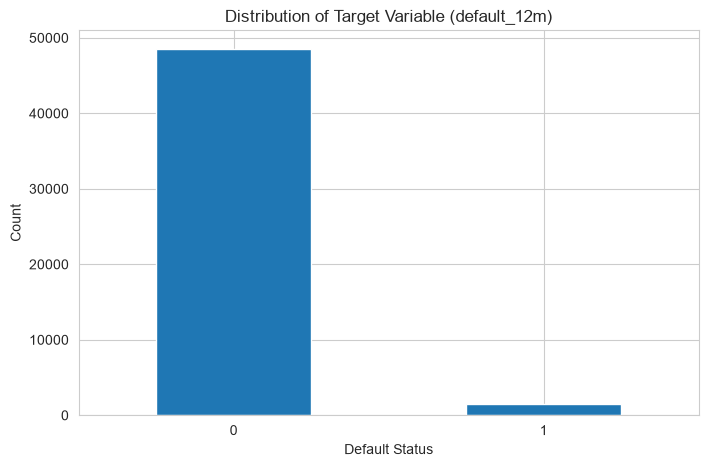

In [178]:
# Target variable distribution
print(f"Default Rate: {df['default_12m'].mean():.2%}")
print(f"\nClass Distribution:")
print(df['default_12m'].value_counts())

# Visualize
plt.figure(figsize=(8, 5))
df['default_12m'].value_counts().plot(kind='bar')
plt.title('Distribution of Target Variable (default_12m)')
plt.xlabel('Default Status')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()


### 2.2 Feature Analysis

TODO: Add your EDA analysis here:
- Distribution plots for numerical features
- Correlation analysis
- Outlier detection
- Relationship between features and target variable
- Analysis of categorical variables


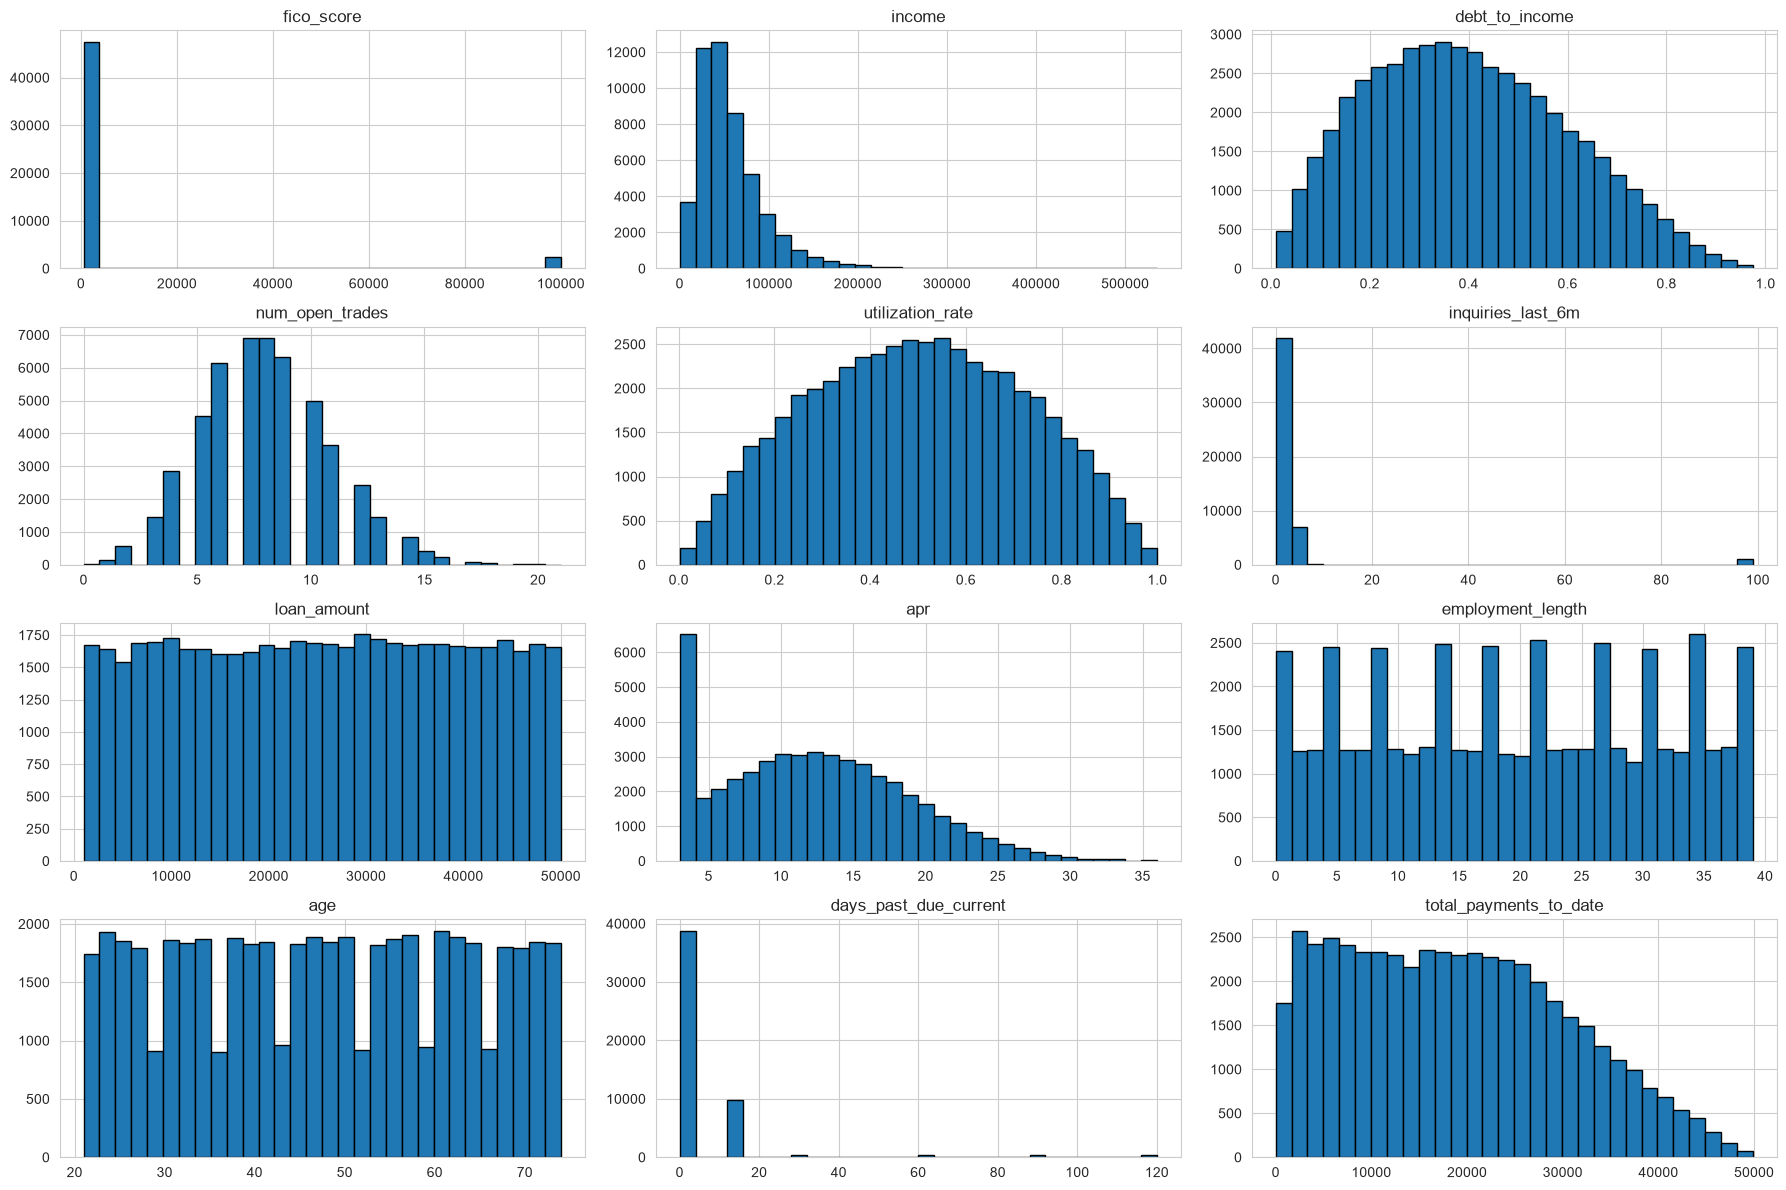

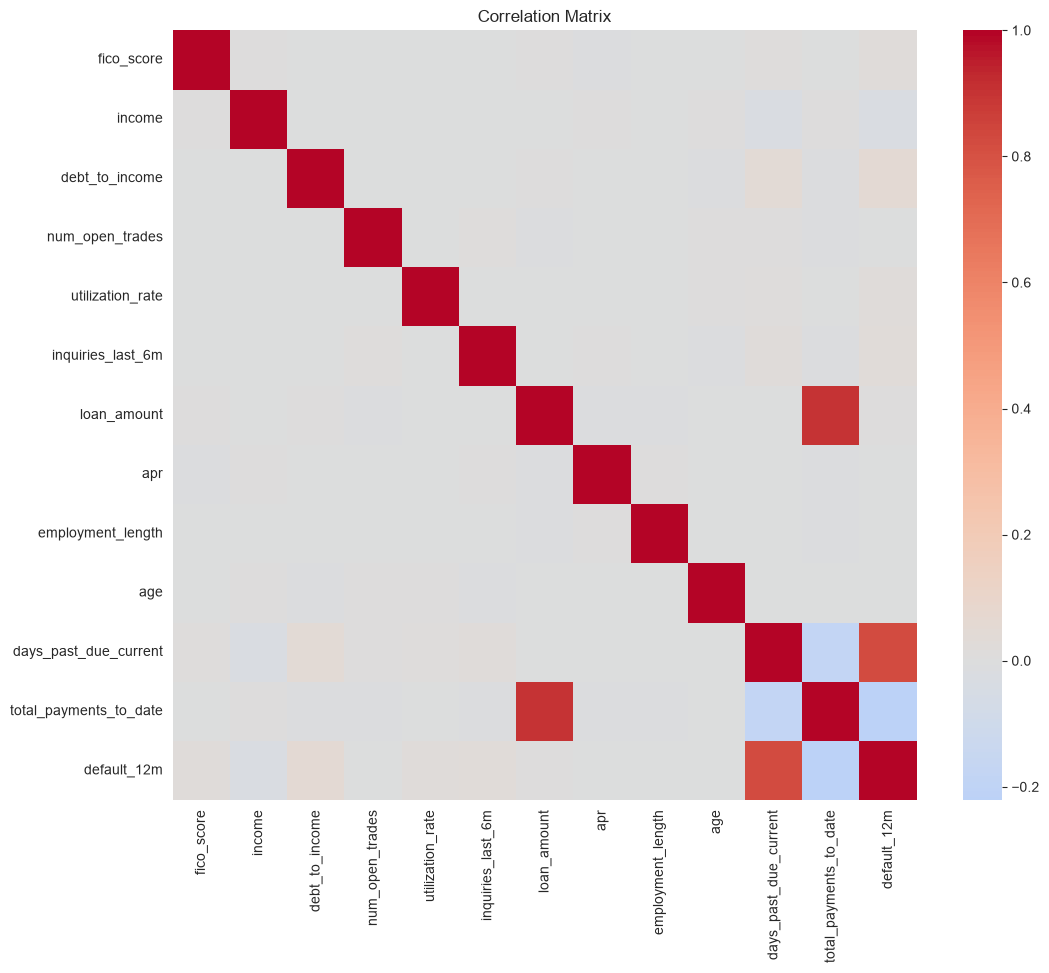

default_12m               1.000000
days_past_due_current     0.822525
debt_to_income            0.053333
inquiries_last_6m         0.028931
utilization_rate          0.018140
fico_score                0.017740
loan_amount               0.003045
age                       0.001775
apr                       0.000952
num_open_trades           0.000839
employment_length        -0.002506
income                   -0.030145
total_payments_to_date   -0.221461
Name: default_12m, dtype: float64


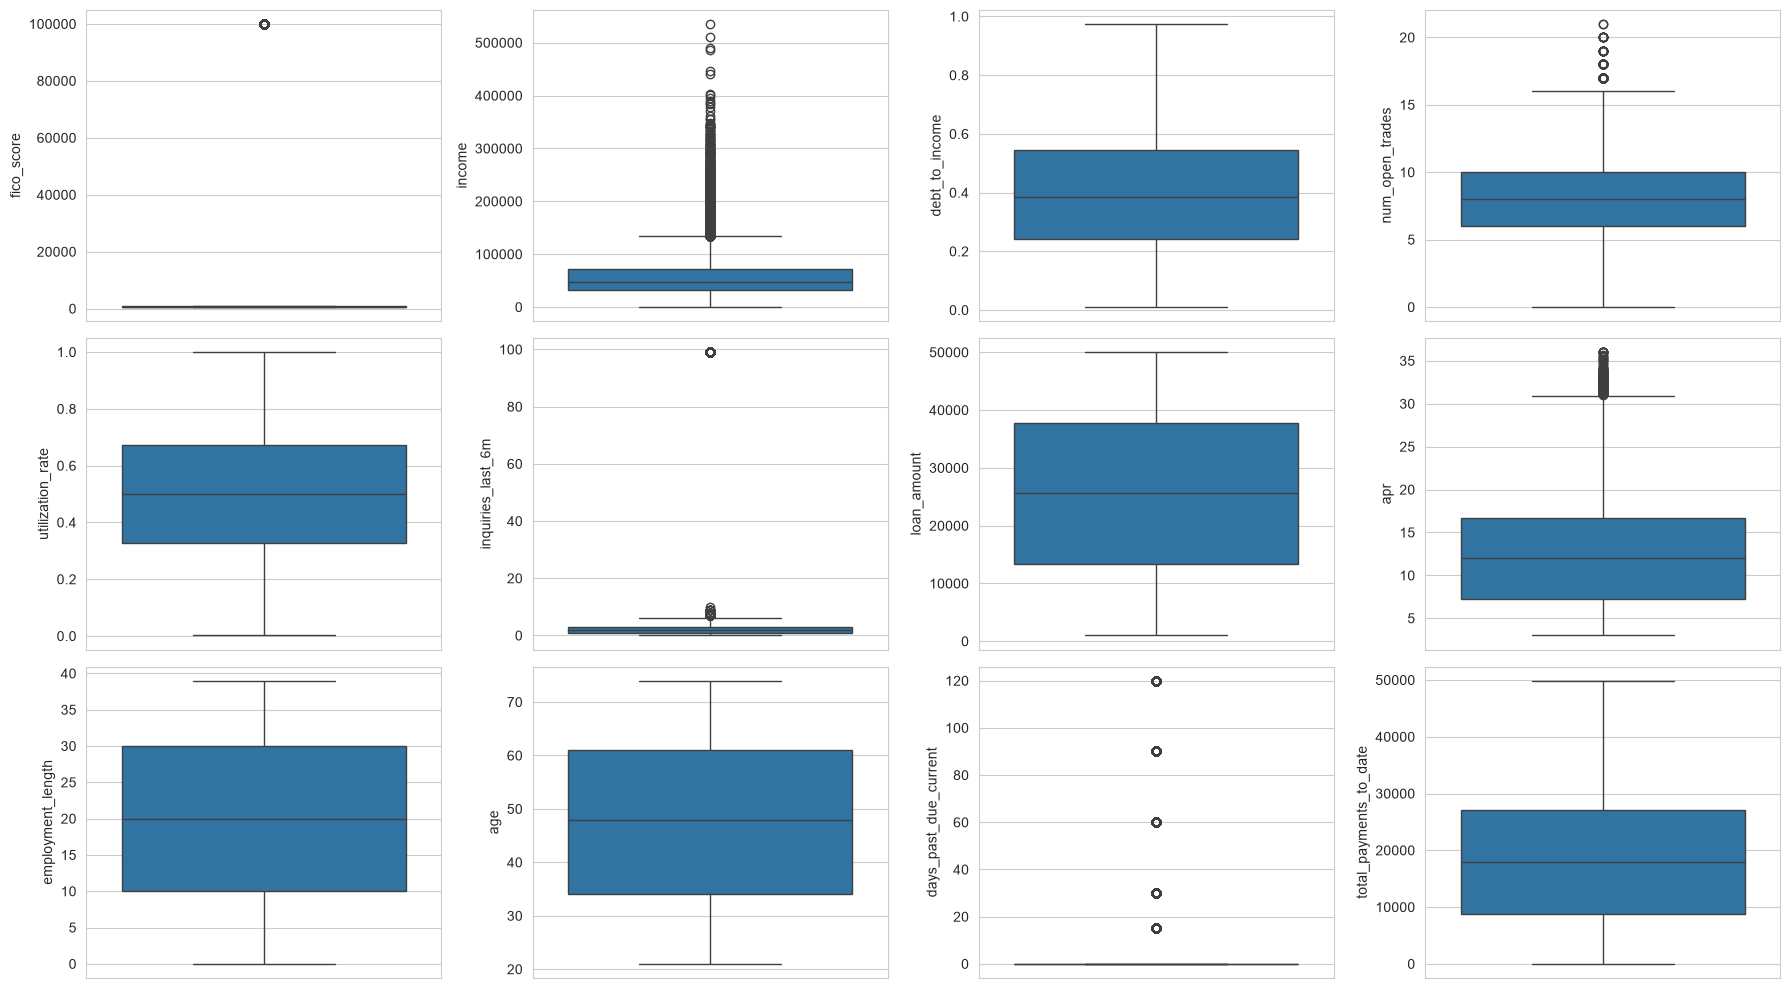

Number of income outliers: 2217


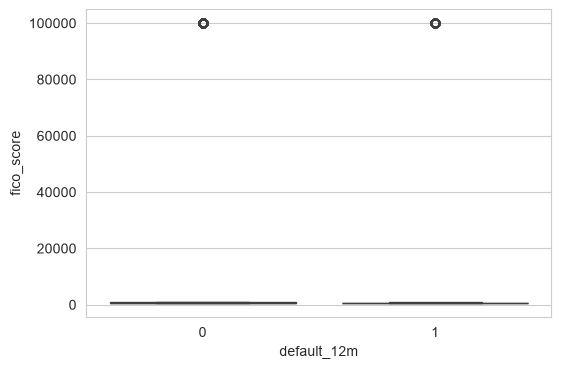

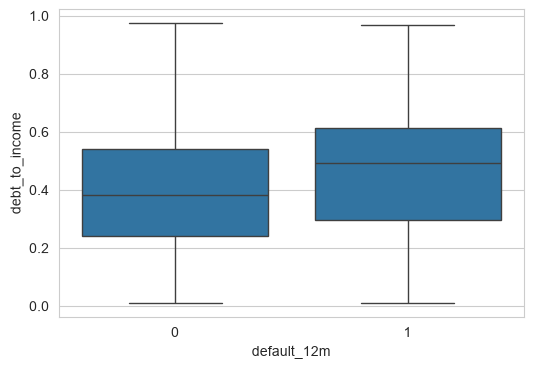

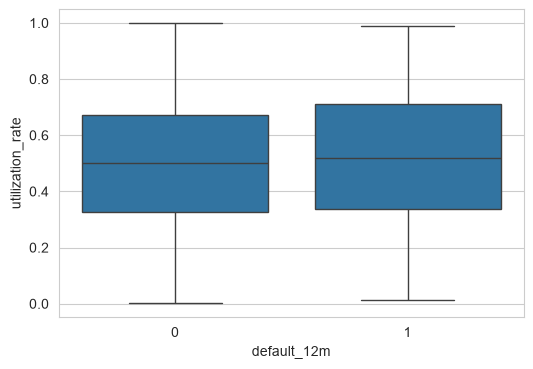

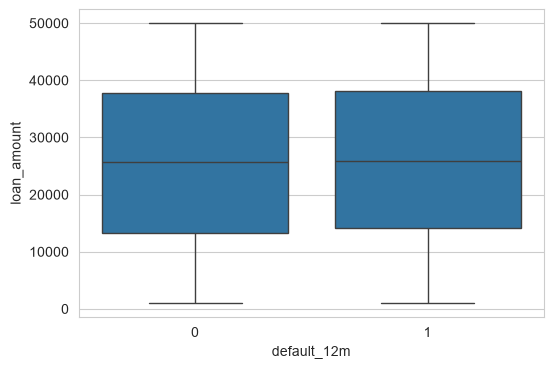

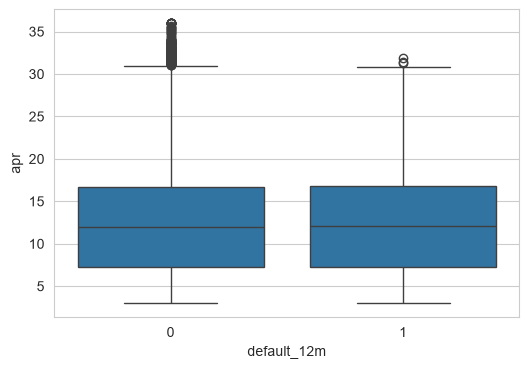

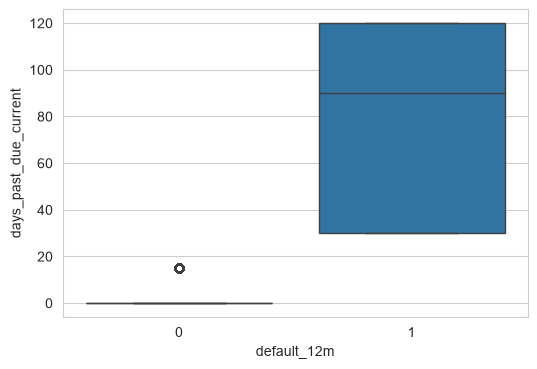

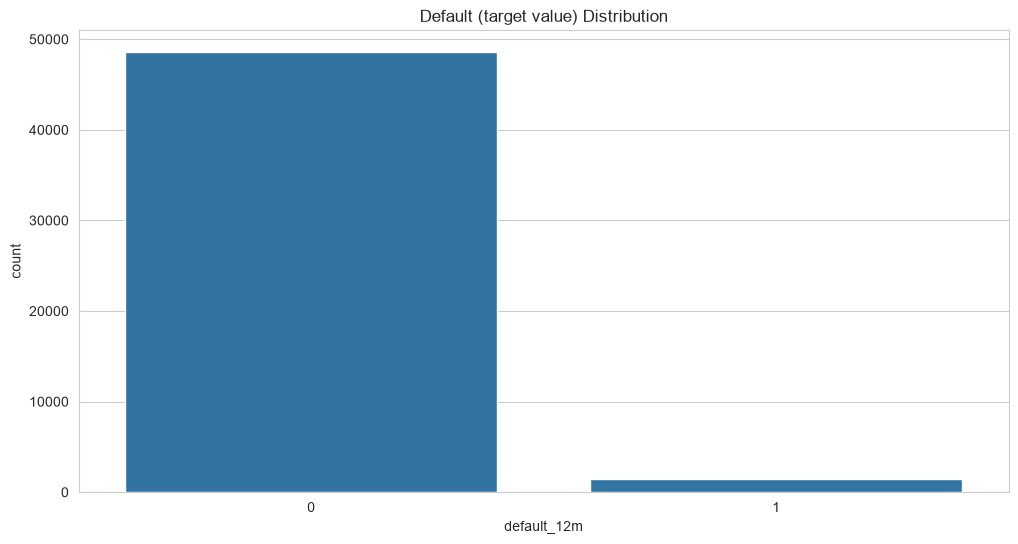

default_12m
0    0.97148
1    0.02852
Name: proportion, dtype: float64

channel:
channel
Direct     24851
Partner    20091
Mail        5058
Name: count, dtype: int64

product_type:
product_type
Personal              15048
Debt_Consolidation    12664
Auto                   9813
Home_Improvement       7391
Business               5084
Name: count, dtype: int64

state:
state
Other    18538
CA        7518
TX        6052
FL        4903
NY        4871
GA        4118
IL        4000
Name: count, dtype: int64

Duplicate Loan_id: 0
Fully duplicate rows: 0
term values: [np.int64(36), np.int64(60)]


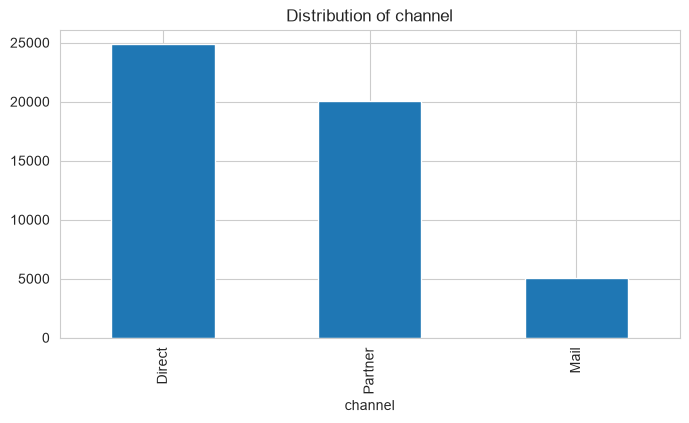

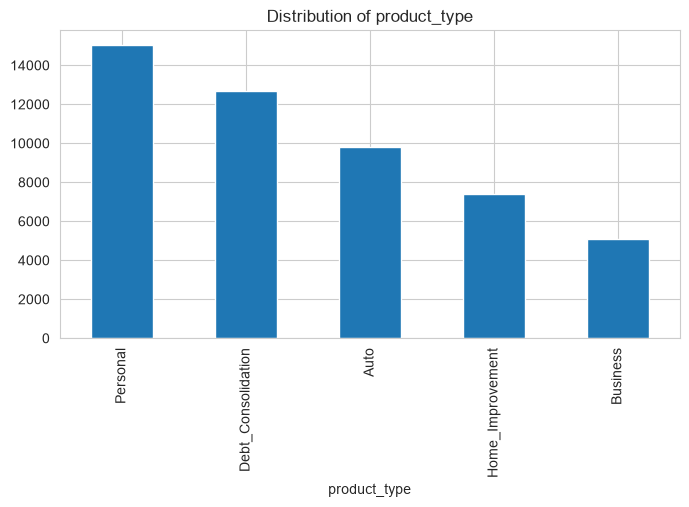

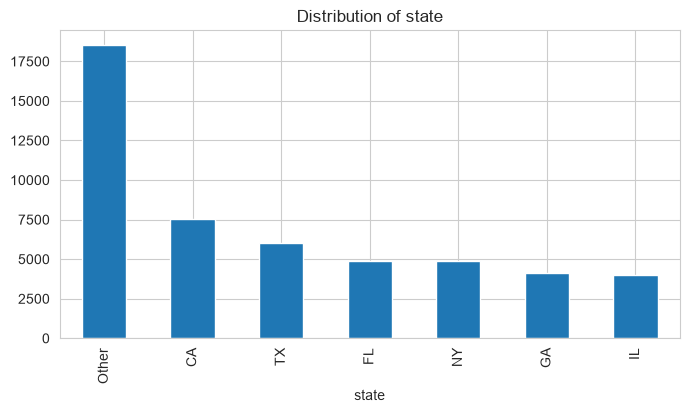

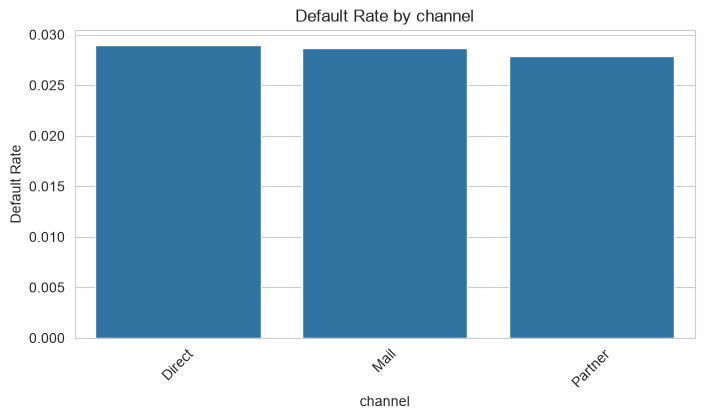

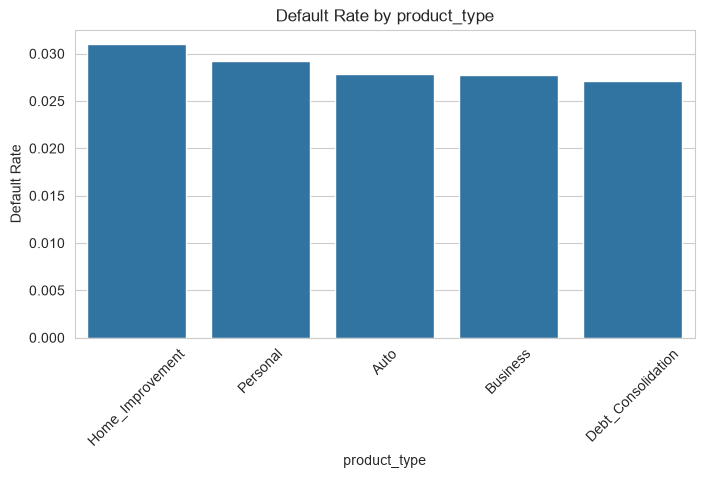

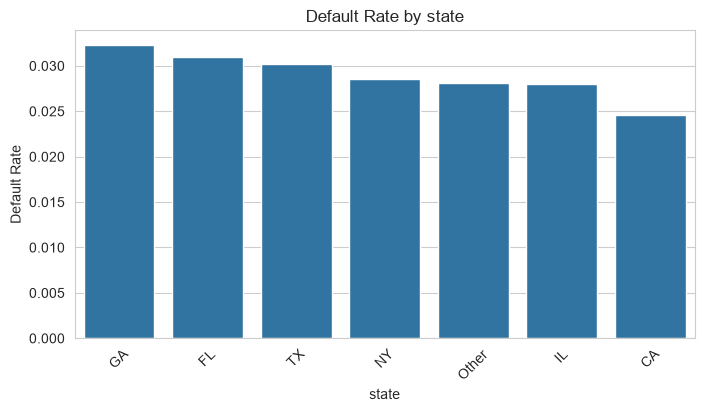

sample_weight by default_12m class:
                 mean     min     max
default_12m                          
0            1.000366  0.8000  1.2000
1            3.008348  2.4002  3.5994
=> Non-defaulters get weight ~1.0, defaulters get weight ~3.0, with almost no overlap.
months_on_book distribution (notice it's ~12 for every vintage -- it's a performance
snapshot taken ~12 months after origination, not information available at origination):
vintage
202404    12.085321
202405    11.938227
202406    11.803017
202407    12.171040
202408    12.394576
202409    12.593918
Name: months_on_book, dtype: float64


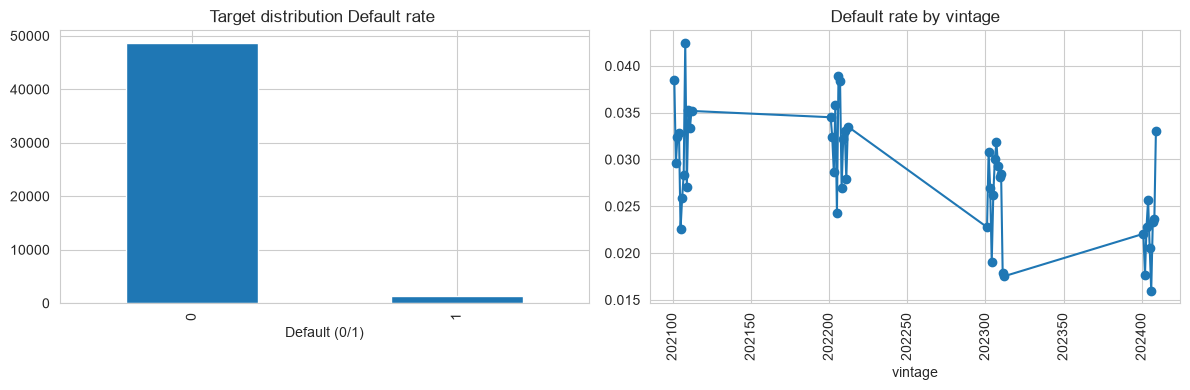

In [179]:
# Your EDA code here
#Distribution Plots for Numerical Features
numerical_features = ['fico_score','income','debt_to_income','num_open_trades','utilization_rate','inquiries_last_6m','loan_amount','apr','employment_length',
'age','days_past_due_current','total_payments_to_date']
df[numerical_features].hist(
    figsize=(18,12),
    bins=30,
    edgecolor='black'
)
plt.tight_layout()
plt.show()

#Correlation Analysis
corr_matrix = df[numerical_features + ['default_12m']].corr()
plt.figure(figsize=(12,10))
sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    center=0,
    annot=False
)
plt.title('Correlation Matrix')
plt.show()

#Check the target variable
corr_with_target = (
    corr_matrix['default_12m']
    .sort_values(ascending=False)
)
print(corr_with_target)

#Outlier Detection
plt.figure(figsize=(18,10))
for i, col in enumerate(numerical_features, 1):
    plt.subplot(3, 4, i)
    sns.boxplot(y=df[col])
plt.tight_layout()
plt.show()
Q1 = df['income'].quantile(0.25)
Q3 = df['income'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
outliers = df[(df['income'] < lower) | (df['income'] > upper)]
print("Number of income outliers:", len(outliers))

#Relationship Between Features and Target Variable
cols=['fico_score','debt_to_income','utilization_rate','loan_amount','apr','days_past_due_current']
for c in cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(x='default_12m',y=c,data=df)
    plt.show()

#target distrubution
sns.countplot(x='default_12m',data=df)
plt.title('Default (target value) Distribution')
plt.show()
print(df['default_12m'].value_counts(normalize=True))

#Categorical Features
cat_cols=['channel','product_type','state']
for i in cat_cols:
    print (f"\n{i}:")
    print (df[i].value_counts())

print ("\nDuplicate Loan_id:",df['loan_id'].duplicated().sum())
print ("Fully duplicate rows:", df.duplicated().sum())
print ("term values:", sorted(df['term'].unique()))

for col in cat_cols:
    plt.figure(figsize=(8,4))
    df[col].value_counts().plot(kind='bar')
    plt.title(f'Distribution of {col}')
    plt.show()

for col in cat_cols:
    default_rate = (df.groupby(col)['default_12m'].mean().sort_values(ascending=False))
    plt.figure(figsize=(8,4))
    sns.barplot(x=default_rate.index,y=default_rate.values)
    plt.xticks(rotation=45)
    plt.title(f'Default Rate by {col}')
    plt.ylabel('Default Rate')
    plt.show()

print("sample_weight by default_12m class:")
print(df.groupby('default_12m')['sample_weight'].describe()[['mean', 'min', 'max']])
print("=> Non-defaulters get weight ~1.0, defaulters get weight ~3.0, with almost no overlap.")
#days_past_due_current / total_payments_to_date / months_on_book 
print("months_on_book distribution (notice it's ~12 for every vintage -- it's a performance")
print("snapshot taken ~12 months after origination, not information available at origination):")
print(df.groupby('vintage')['months_on_book'].mean().tail(6))


fig, axes = plt.subplots(1,2,figsize=(12,4))
df.default_12m.value_counts().sort_index().plot(kind="bar",ax=axes[0])
axes[0].set_title("Target distribution Default rate "); axes[0].set_xlabel("Default (0/1)")
df.groupby("vintage").default_12m.mean().plot(ax=axes[1],marker="o")
axes[1].set_title("Default rate by vintage"); axes[1].tick_params(axis="x",rotation=90)
plt.tight_layout()



## 3. Data Preprocessing & Feature Engineering

### 3.1 Handle Missing Values


In [180]:
# Your preprocessing code here
# Check missing values in each column
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0])
missing_percentage = (
    df.isnull().mean() * 100
).sort_values(ascending=False)
print(missing_percentage[missing_percentage > 0])
print(df.isnull().sum().sum())
from sklearn.impute import SimpleImputer
num_imputer = SimpleImputer(strategy='median')
df[numerical_features] = num_imputer.fit_transform(df[numerical_features])
cat_imputer = SimpleImputer(strategy='most_frequent')
df[cat_cols] = cat_imputer.fit_transform(df[cat_cols])
#fill missing for categorical variable by "unknown"
df[cat_cols] = (df[cat_cols].fillna("Unknown"))
#deal with special vaules 
df_proc = df.copy()
SPECIAL_VALUES = {'fico_score': 99999,'income': -1,'inquiries_last_6m': 99,}
for col, sentinel in SPECIAL_VALUES.items():
    df_proc[f'{col}_missing'] = (df_proc[col] == sentinel).astype(int)
    df_proc[col] = df_proc[col].replace(sentinel, np.nan)
for col in SPECIAL_VALUES:
    rates = df_proc.groupby(f'{col}_missing')['default_12m'].mean()
    print(f"{col}: default rate when present={rates.get(0, float('nan')):.3%},missing={rates.get(1, float('nan')):.3%}")
df_proc[['fico_score','income','inquiries_last_6m']].isna().sum()

imputer = SimpleImputer(strategy='median')
numeric_cols = [
    'fico_score',
    'income',
    'inquiries_last_6m'
]
df_proc[numeric_cols] = imputer.fit_transform(
    df_proc[numeric_cols]
)
df_proc[['fico_score','income','inquiries_last_6m']].isna().sum()


Series([], dtype: int64)
Series([], dtype: float64)
0
fico_score: default rate when present=2.783%,missing=4.160%
income: default rate when present=2.757%,missing=5.933%
inquiries_last_6m: default rate when present=2.786%,missing=6.100%


fico_score           0
income               0
inquiries_last_6m    0
dtype: int64

### 3.2 Handle Outliers


fico_score 0
income 2396
debt_to_income 0
num_open_trades 172
utilization_rate 0
inquiries_last_6m 203
loan_amount 0
apr 154
employment_length 0
age 0
days_past_due_current 11195
total_payments_to_date 0
Invalid employment records: 13848
fico_score 0
income 2396
debt_to_income 0
num_open_trades 172
utilization_rate 0
inquiries_last_6m 203
loan_amount 0
apr 154
employment_length 908
age 0
days_past_due_current 11195
total_payments_to_date 0


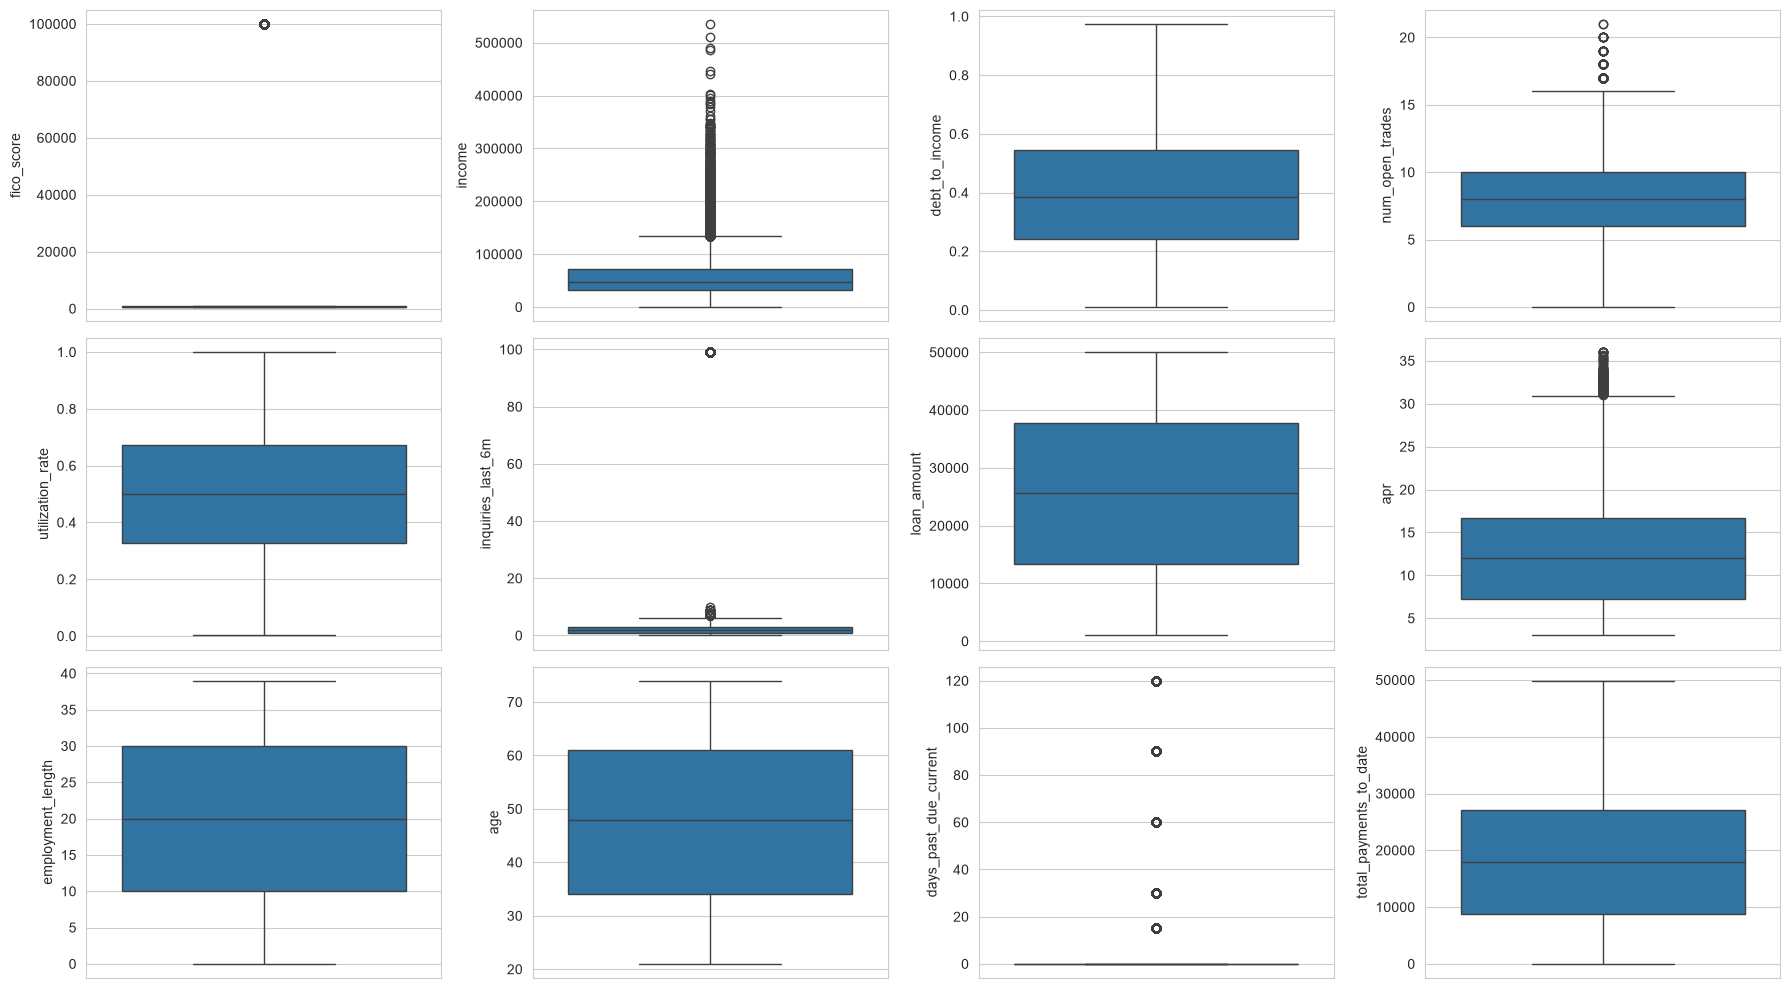

In [181]:
# Your outlier handling code here
#using IQR method
def detect_outliers_iqr(df_proc, column):
    Q1 = df_proc[column].quantile(0.25)
    Q3 = df_proc[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df_proc[(df_proc[column] < lower_bound) | (df_proc[column] > upper_bound)]
    return len(outliers)
# Assume minimum working age = 16
for col in numerical_features:
    print(col, detect_outliers_iqr(df_proc, col))
employment_issue = (
    df_proc['employment_length']
    >
    (df_proc['age'] - 16)
)
print("Invalid employment records:",employment_issue.sum())

# Create quality flag
df_proc['employment_length_issue'] = (employment_issue).astype(int)
# Replace impossible values
df_proc.loc[employment_issue,'employment_length'] = np.nan
df_proc['employment_length'] = (df_proc['employment_length'].fillna(df_proc['employment_length'].median()))

for col in numerical_features:
    print(col, detect_outliers_iqr(df_proc, col))
plt.figure(figsize=(18,10))
for i, col in enumerate(numerical_features, 1):
    plt.subplot(3, 4, i)
    sns.boxplot(y=df[col])
plt.tight_layout()
plt.show()
#for highly right-skewed variables (income,loan_amount), the log transformation 
df_proc['income_log'] = np.log1p(df_proc['income'])
df_proc['loan_amount_log'] = np.log1p(df_proc['loan_amount'])


### 3.3 Feature Engineering


In [182]:
df_feat=df_proc.copy()
#update date format
df_feat['origination_date'] = pd.to_datetime(df_feat['origination_date'])
df_feat['origination_year'] = df_feat['origination_date'].dt.year
df_feat['origination_month'] = df_feat['origination_date'].dt.month
df_feat['origination_quarter'] = df_feat['origination_date'].dt.quarter
#utilization % 80%
df_feat['high_utilization'] = (df_feat['utilization_rate'] > 0.8).astype(int)
#DTI 40% and 80%
df_feat['high_dti'] = (df_feat['debt_to_income'] > 0.8).astype(int)
df_feat['medium_dti'] = ( (df_feat['debt_to_income'] > 0.4) & (df_feat['debt_to_income'] <= 0.8)).astype(int)
df_feat['low_dti'] = (df_feat['debt_to_income'] <= 0.4).astype(int)
#Payment Performance %
df_feat['payment_ratio'] = (df_feat['total_payments_to_date']/df_feat['loan_amount'])
#APR/FICO Risk
df_feat['apr_fico_ratio'] = (df_feat['apr']/df_feat['fico_score'])
#Inquiry Intensity
df_feat['inquiry_per_trade'] = (df_feat['inquiries_last_6m']/(df_feat['num_open_trades'] + 1))
#Loan-to-Income Ratio
df_feat['loan_income_ratio'] = (df_feat['loan_amount']/df_feat['income'])
#age bands
df_feat['age_group'] = pd.cut(df_feat['age'],bins=[18, 30, 45, 60, 100],labels=['Young','Middle','Mature','Senior'])
#Delinquency Indicator
df_feat['has_delinquency'] = (df_feat['days_past_due_current'] > 0).astype(int)
#FICO buckets
df_feat['fico_bucket'] = pd.cut(df_feat['fico_score'],bins=[300, 580, 670, 740, 800, 850],labels=['Poor','Fair','Good','Very_Good','Excellent'])
#log income
df_feat['log_income'] = np.log1p(df_feat['income'])
#loan to income
df_feat['loan_to_income'] = df_feat['loan_amount'] / df_feat['income'].clip(lower=1000)
#est monthly payment
rate_m = df_feat['apr'] / 100 / 12
n_pmts = df_feat['term']
df_feat['est_monthly_payment'] = (
    df_feat['loan_amount'] * rate_m * (1 + rate_m) ** n_pmts / ((1 + rate_m) ** n_pmts - 1)
)
#payment to income
df_feat['payment_to_income'] = (df_feat['est_monthly_payment'] * 12) / df_feat['income'].clip(lower=1000)


### 3.4 Encode Categorical Variables


In [183]:
#Remove Unnecessary Features
df_feat.drop(columns=['loan_id','origination_date'],inplace=True)
categorical_features = ['channel','product_type','state','age_group','fico_bucket']
leak_cols = ['sample_weight',
    'origination_year',
    'origination_month',
    'origination_quarter',
     'has_delinquency',
    'days_past_due_current',
    'total_payments_to_date',
    'payment_ratio',
    'payment_to_income']

df_feat.drop(columns=leak_cols, inplace=True)
df_feat = pd.get_dummies(df_feat,columns=categorical_features,drop_first=True)
print(df_feat.shape)
print(df.head())

df_feat = df_feat.astype(
    {col: int for col in df_feat.select_dtypes('bool').columns}
)
X = df_feat.drop('default_12m', axis=1)
y = df_feat['default_12m']
print("Features:", X.shape)
print("Target:", y.shape)



(50000, 49)
       loan_id origination_date  vintage  months_on_book  fico_score   income  \
0  LOAN_000000       2024-03-01   202403               6       738.0  81758.0   
1  LOAN_000001       2023-05-01   202305              23       818.0  21891.0   
2  LOAN_000002       2022-03-01   202203               1       800.0  82072.0   
3  LOAN_000003       2024-07-01   202407               0       657.0  40335.0   
4  LOAN_000004       2021-08-01   202108               9       771.0  11733.0   

   debt_to_income  num_open_trades  utilization_rate  inquiries_last_6m  ...  \
0          0.0770              7.0            0.2484                0.0  ...   
1          0.6960              8.0            0.5129               99.0  ...   
2          0.1439             10.0            0.5875                1.0  ...   
3          0.1670              8.0            0.2927                1.0  ...   
4          0.0337              3.0            0.1871                0.0  ...   

     apr  channel   

### 3.5 Train/Test Split


In [184]:
# Split data
# X_train, X_test, y_train, y_test = train_test_split(...)
#70% Train + 15% Cross Validation + 15% Test
from sklearn.model_selection import train_test_split
from sklearn.model_selection import TimeSeriesSplit
# Sort by origination vintage
df_feat = df_feat.sort_values('vintage').reset_index(drop=True)
X = df_feat.drop(
    columns=['default_12m', 'vintage'],
    errors='ignore'
)
y = df_feat['default_12m']
vintage = df_feat['vintage']
# Unique vintages sorted chronologically
unique_vintages = sorted(vintage.unique())
# Split vintages chronologically
n_vintages = len(unique_vintages)
train_end = int(n_vintages * 0.70)
validation_end = int(n_vintages * 0.85)
train_vintages = unique_vintages[:train_end]
validation_vintages = unique_vintages[train_end:validation_end]
test_vintages = unique_vintages[validation_end:]
# Create Train / Validation / Test datasets
train_idx = vintage.isin(train_vintages)
validation_idx = vintage.isin(validation_vintages)
test_idx = vintage.isin(test_vintages)
X_train = X.loc[train_idx]
y_train = y.loc[train_idx]
X_validation = X.loc[validation_idx]
y_validation = y.loc[validation_idx]
X_test = X.loc[test_idx]
y_test = y.loc[test_idx]
print("Train Vintage:", train_vintages[0], "-", train_vintages[-1])
print("Validation Vintage:", validation_vintages[0], "-", validation_vintages[-1])
print("Test Vintage:", test_vintages[0], "-", test_vintages[-1])
print("\nTraining Features:", X_train.shape)
print("Validation Features:", X_validation.shape)
print("Testing Features:", X_test.shape)
print("\nTraining Target:", y_train.shape)
print("Validation Target:", y_validation.shape)
print("Testing Target:", y_test.shape)

from sklearn.model_selection import TimeSeriesSplit
k_folder_splits = 5
tscv = TimeSeriesSplit(n_splits=k_folder_splits)
train_vintage_array = np.array(train_vintages)
cv_splits = []
for fold, (train_vintage_idx, validation_vintage_idx) in enumerate(
    tscv.split(train_vintage_array),
    start=1
):
    fold_train_vintages = train_vintage_array[train_vintage_idx]
    fold_validation_vintages = train_vintage_array[validation_vintage_idx]
    fold_train_idx = vintage.isin(fold_train_vintages)
    fold_validation_idx = vintage.isin(fold_validation_vintages)
    X_fold_train = X.loc[fold_train_idx]
    y_fold_train = y.loc[fold_train_idx]
    X_fold_validation = X.loc[fold_validation_idx]
    y_fold_validation = y.loc[fold_validation_idx]
    cv_splits.append(
        (
            X_fold_train.index,
            X_fold_validation.index
        )
    )
    print(f"\nFold {fold}")
    print(
        f"Train Vintage: "
        f"{fold_train_vintages[0]} - {fold_train_vintages[-1]}"
    )
    print(
        f"Validation Vintage: "
        f"{fold_validation_vintages[0]} - "
        f"{fold_validation_vintages[-1]}"
    )
    print("Train Shape:", X_fold_train.shape)
    print("Validation Shape:", X_fold_validation.shape)
    print("Train Default Rate:", y_fold_train.mean())
    print("Validation Default Rate:", y_fold_validation.mean())

Train Vintage: 202101 - 202307
Validation Vintage: 202308 - 202402
Test Vintage: 202403 - 202409

Training Features: (34597, 47)
Validation Features: (7639, 47)
Testing Features: (7764, 47)

Training Target: (34597,)
Validation Target: (7639,)
Testing Target: (7764,)

Fold 1
Train Vintage: 202101 - 202106
Validation Vintage: 202107 - 202111
Train Shape: (6605, 47)
Validation Shape: (5518, 47)
Train Default Rate: 0.03028009084027252
Validation Default Rate: 0.03334541500543675

Fold 2
Train Vintage: 202101 - 202111
Validation Vintage: 202112 - 202204
Train Shape: (12123, 47)
Validation Shape: (5615, 47)
Train Default Rate: 0.03167532788913635
Validation Default Rate: 0.03330365093499555

Fold 3
Train Vintage: 202101 - 202204
Validation Vintage: 202205 - 202209
Train Shape: (17738, 47)
Validation Shape: (5613, 47)
Train Default Rate: 0.032190776863231484
Validation Default Rate: 0.032068412613575625

Fold 4
Train Vintage: 202101 - 202209
Validation Vintage: 202210 - 202302
Train Shape: (

In [185]:
X_train.dtypes
X_train.select_dtypes(include=['object']).columns
X_train.isna().sum()[X_train.isna().sum() > 0]

Series([], dtype: int64)

## 4. Model Training

### 4.1 Model 1: Logistic Regression


In [186]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        max_iter=1000,
         class_weight='balanced',
        random_state=42
    ))
])
cv_auc_scores = cross_val_score(
    lr_pipeline,
    X_train,
    y_train,
    cv=cv_splits,
    scoring='roc_auc',
    n_jobs=-1
)
print("Fold AUC Scores:")
print(cv_auc_scores)
print("Mean AUC:", cv_auc_scores.mean())
print("Std AUC:", cv_auc_scores.std())
corr = df_feat.corr(numeric_only=True)
corr['default_12m'].sort_values(
    key=abs,
    ascending=False
).head(20)


Fold AUC Scores:
[0.65771364 0.67579968 0.68378326 0.72839382 0.68501275]
Mean AUC: 0.6861406297542967
Std AUC: 0.02326882182336956


default_12m                  1.000000
fico_score                  -0.073597
fico_bucket_Fair             0.054216
debt_to_income               0.053333
low_dti                     -0.045958
fico_bucket_Very_Good       -0.040770
medium_dti                   0.039668
income_missing               0.032555
income_log                  -0.030813
log_income                  -0.030813
high_utilization             0.028617
inquiries_last_6m_missing    0.027876
fico_bucket_Good            -0.025482
fico_bucket_Excellent       -0.025334
income                      -0.023936
vintage                     -0.022006
loan_income_ratio            0.020746
loan_to_income               0.020746
high_dti                     0.019984
utilization_rate             0.018140
Name: default_12m, dtype: float64

### 4.2 Model 2: Gradient Boosting / XGBoost / LightGBM


In [187]:
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42,
    n_jobs=1
)

cv_auc_scores_xgb = cross_val_score(
    xgb_model,
    X_train,
    y_train,
    cv=cv_splits,
    scoring='roc_auc',
    n_jobs=-1
)

print("Temporal CV Fold AUC Scores:")
print(cv_auc_scores_xgb)

print(f"Mean CV AUC: {cv_auc_scores_xgb.mean():.4f}")
print(f"Std CV AUC:  {cv_auc_scores_xgb.std():.4f}")
# Train final XGBoost model on the training set
xgb_model.fit(X_train, y_train)
# Predict probabilities on the test set
test_prob = xgb_model.predict_proba(X_test)[:, 1]


Temporal CV Fold AUC Scores:
[0.61446973 0.66654483 0.66106152 0.72555392 0.66702578]
Mean CV AUC: 0.6669
Std CV AUC:  0.0353


## 5. Model Evaluation & Comparison

### 5.1 Calculate Metrics (AUC, KS, Precision-Recall)


Mean CV AUC by Logistic Regression: 0.6861406297542967
Mean CV AUC by XGBoost: 0.6669311547314681
KS by Logistic Regression: 0.3099400788424902
KS by XGBoost: 0.3063547566067888


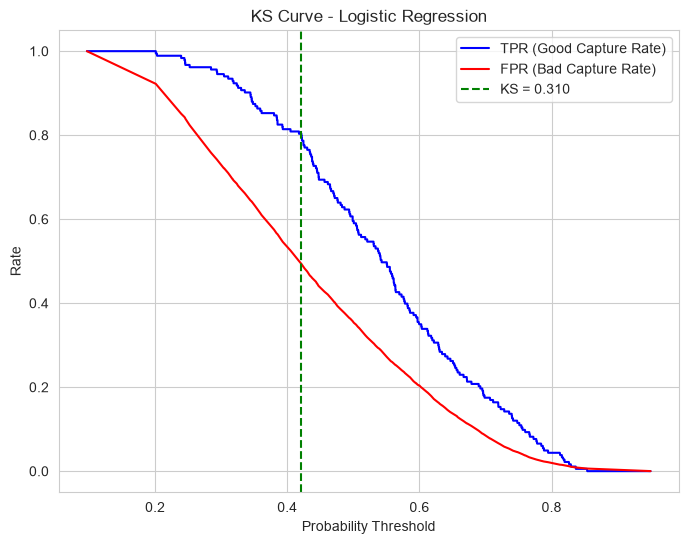

KS Statistic = 0.3099


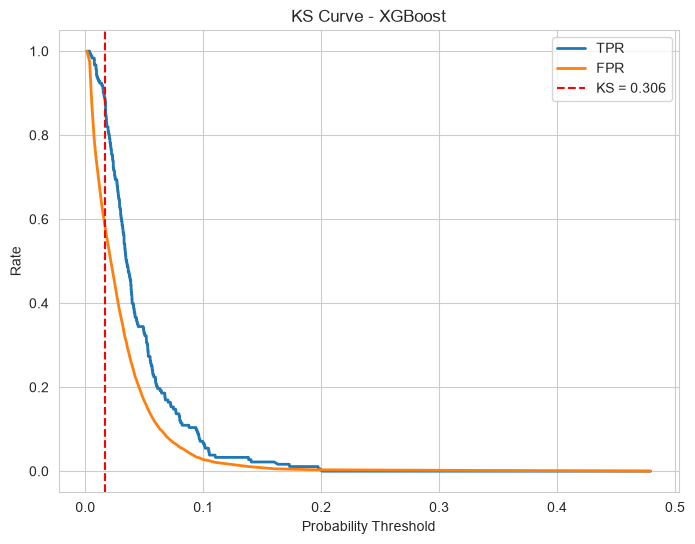

KS Statistic = 0.3064
PR AUC by Logistic Regression: 0.041318829637111115
PR AUC by XGBoost: 0.041375639596412585


In [188]:
# Cross Validation
cv_auc_scores = cross_val_score(
    lr_pipeline,
    X_train,
    y_train,
    cv=cv_splits,
    scoring='roc_auc'
)

print("Mean CV AUC by Logistic Regression:", cv_auc_scores.mean())
print("Mean CV AUC by XGBoost:", cv_auc_scores_xgb.mean())

#final model by lr by cross validation
lr_pipeline.fit(X_train, y_train)
y_prob_lr = lr_pipeline.predict_proba(
    X_test
)[:, 1]
# final model by xgb by cross validation
xgb_model.fit(X_train, y_train)
y_prob_xgb = xgb_model.predict_proba(
    X_test
)[:, 1]
#KS
from sklearn.metrics import roc_curve
import numpy as np
def ks_score(y_true, y_prob):
    fpr, tpr, _ = roc_curve(
        y_true,
        y_prob)
    return np.max(tpr - fpr)
lr_pipeline.fit(X_train, y_train)
y_prob_lr = lr_pipeline.predict_proba(
    X_test
)[:,1]
ks_lr = ks_score(
    y_test,
    y_prob_lr
)
print("KS by Logistic Regression:", ks_lr)
xgb_model.fit(X_train, y_train)
y_prob_xgb = xgb_model.predict_proba(
    X_test
)[:,1]
ks_xgb = ks_score(
    y_test,
    y_prob_xgb
)
print("KS by XGBoost:", ks_xgb)
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob_lr
)
# KS Value
ks = np.max(tpr - fpr)
# KS Point
ks_idx = np.argmax(tpr - fpr)
plt.figure(figsize=(8,6))
plt.plot(
    thresholds,
    tpr,
    label='TPR (Good Capture Rate)',
    color='blue'
)
plt.plot(
    thresholds,
    fpr,
    label='FPR (Bad Capture Rate)',
    color='red'
)
plt.axvline(
    thresholds[ks_idx],
    linestyle='--',
    color='green',
    label=f'KS = {ks:.3f}'
)
plt.xlabel('Probability Threshold')
plt.ylabel('Rate')
plt.title('KS Curve - Logistic Regression')
plt.legend()
plt.grid(True)
plt.show()
print(f"KS Statistic = {ks:.4f}")
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob_xgb
)
ks = np.max(tpr - fpr)
ks_idx = np.argmax(tpr - fpr)
plt.figure(figsize=(8,6))
plt.plot(
    thresholds,
    tpr,
    label='TPR',
    linewidth=2
)
plt.plot(
    thresholds,
    fpr,
    label='FPR',
    linewidth=2
)
plt.axvline(
    x=thresholds[ks_idx],
    color='red',
    linestyle='--',
    label=f'KS = {ks:.3f}'
)
plt.xlabel('Probability Threshold')
plt.ylabel('Rate')
plt.title('KS Curve - XGBoost')
plt.legend()
plt.grid(True)
plt.show()
print(f"KS Statistic = {ks:.4f}")
#precision-recall AUC
from sklearn.metrics import average_precision_score
pr_auc_lr = average_precision_score(
    y_test,
    y_prob_lr
)
print("PR AUC by Logistic Regression:", pr_auc_lr)
pr_auc_xgb = average_precision_score(
    y_test,
    y_prob_xgb
)
print("PR AUC by XGBoost:", pr_auc_xgb)

### 5.2 ROC Curves


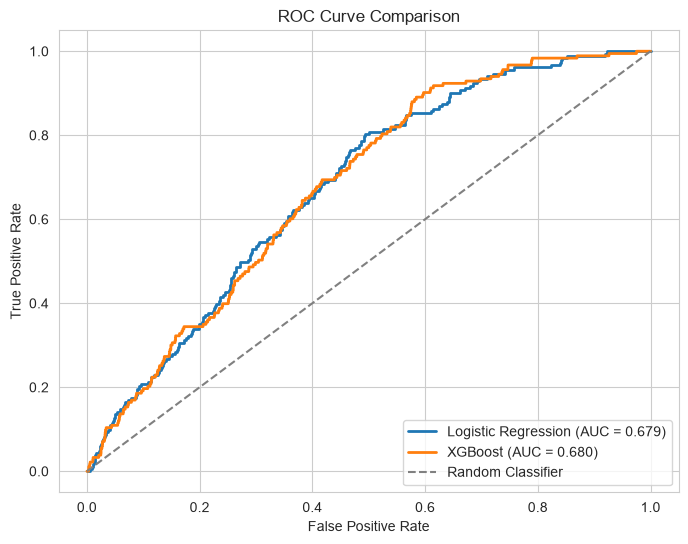

In [189]:
# Plot ROC curves
from sklearn.metrics import roc_curve, roc_auc_score
# Logistic Regression
fpr_lr, tpr_lr, _ = roc_curve(
    y_test,
    y_prob_lr
)
auc_lr = roc_auc_score(
    y_test,
    y_prob_lr
)
# XGBoost
fpr_xgb, tpr_xgb, _ = roc_curve(
    y_test,
    y_prob_xgb
)
auc_xgb = roc_auc_score(
    y_test,
    y_prob_xgb
)
import matplotlib.pyplot as plt
plt.figure(figsize=(8,6))
# Logistic Regression
plt.plot(
    fpr_lr,
    tpr_lr,
    linewidth=2,
    label=f'Logistic Regression (AUC = {auc_lr:.3f})'
)
# XGBoost
plt.plot(
    fpr_xgb,
    tpr_xgb,
    linewidth=2,
    label=f'XGBoost (AUC = {auc_xgb:.3f})'
)
plt.plot(
    [0,1],
    [0,1],
    linestyle='--',
    color='gray',
    label='Random Classifier'
)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


In [190]:
from scipy.stats import ks_2samp
from sklearn.metrics import roc_auc_score
def ks_statistic(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    pred_default = y_pred[y_true == 1]
    pred_non_default = y_pred[y_true == 0]
    if len(pred_default) == 0 or len(pred_non_default) == 0:
        return np.nan
    return ks_2samp(
        pred_default,
        pred_non_default
    ).statistic
test_frame = df_feat.loc[test_mask].copy()
test_frame["predicted_pd"] = test_prob
vintage_perf = test_frame.groupby("vintage").apply(
    lambda g: pd.Series({
        "n": len(g),
        "default_rate": g["default_12m"].mean(),
        "mean_predicted_pd": g["predicted_pd"].mean(),
        "auc": (
            roc_auc_score(g["default_12m"], g["predicted_pd"])
            if g["default_12m"].nunique() > 1
            else np.nan
        ),
        "ks": (
            ks_statistic(g["default_12m"], g["predicted_pd"])
            if g["default_12m"].nunique() > 1
            else np.nan
        )
    }),
    include_groups=False
).reset_index()
vintage_perf

,vintage,n,default_rate,mean_predicted_pd,auc,ks
0,202403,1140.0,0.022807,0.029707,0.700801,0.352852
1,202404,1090.0,0.025688,0.030364,0.672686,0.356067
2,202405,1117.0,0.020591,0.029105,0.679000,0.374811
3,202406,1127.0,0.015972,0.030015,0.688809,0.415690
4,202407,1029.0,0.023324,0.030372,0.637562,0.314552
5,202408,1143.0,0.023622,0.030687,0.703206,0.417563
6,202409,1118.0,0.033095,0.029635,0.677051,0.341876


In [191]:
test_results = pd.DataFrame({
    "y_true": np.asarray(y_test),
    "predicted_pd": np.asarray(test_prob)
})
test_results["decile"] = pd.qcut(
    test_results["predicted_pd"].rank(method="first"),
    10,
    labels=False
)
decile_summary = (
    test_results
    .groupby("decile", observed=True)
    .agg(
        count=("y_true", "count"),
        avg_predicted_pd=("predicted_pd", "mean"),
        actual_default_rate=("y_true", "mean"),
        defaults=("y_true", "sum")
    )
    .reset_index()
)
decile_summary["avg_predicted_pd"] = (
    decile_summary["avg_predicted_pd"] * 100
)
decile_summary["actual_default_rate"] = (
    decile_summary["actual_default_rate"] * 100
)
decile_summary = decile_summary.sort_values(
    "decile", ascending=False
)
decile_summary["avg_predicted_pd"] = (
    decile_summary["avg_predicted_pd"].round(2).astype(str) + "%"
)
decile_summary["actual_default_rate"] = (
    decile_summary["actual_default_rate"].round(2).astype(str) + "%"
)
display(decile_summary)

,decile,count,avg_predicted_pd,actual_default_rate,defaults
9,9,777,9.69%,4.5%,35
8,8,776,5.38%,3.61%,28
7,7,776,4.03%,3.48%,27
6,6,777,3.18%,3.73%,29
5,5,776,2.51%,2.71%,21
4,4,776,1.9%,2.96%,23
3,3,777,1.35%,0.9%,7
2,2,776,0.92%,1.29%,10
1,1,776,0.61%,0.13%,1
0,0,777,0.4%,0.26%,2


### 5.3 Precision-Recall Curves


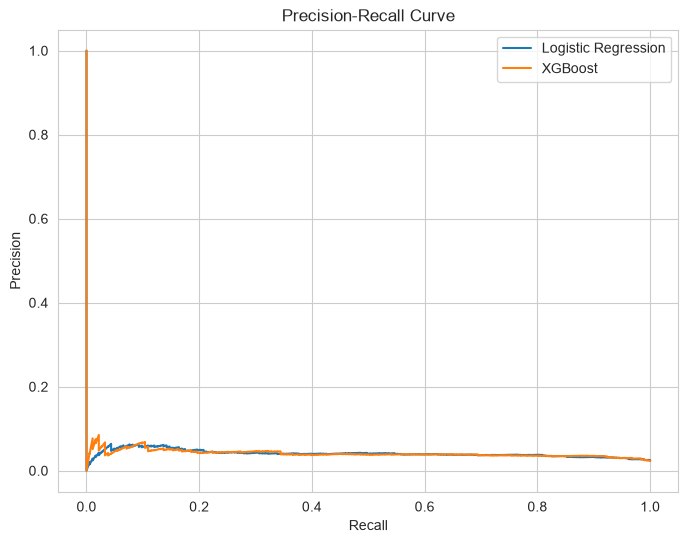

In [192]:
# Plot precision-recall curves
precision_lr, recall_lr, _ = precision_recall_curve(
    y_test,
    y_prob_lr
)
precision_xgb, recall_xgb, _ = precision_recall_curve(
    y_test,
    y_prob_xgb
)
plt.figure(figsize=(8,6))
plt.plot(
    recall_lr,
    precision_lr,
    label='Logistic Regression'
)
plt.plot(
    recall_xgb,
    precision_xgb,
    label='XGBoost'
)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.show()

## 6. Model Interpretation

### 6.1 Feature Importance


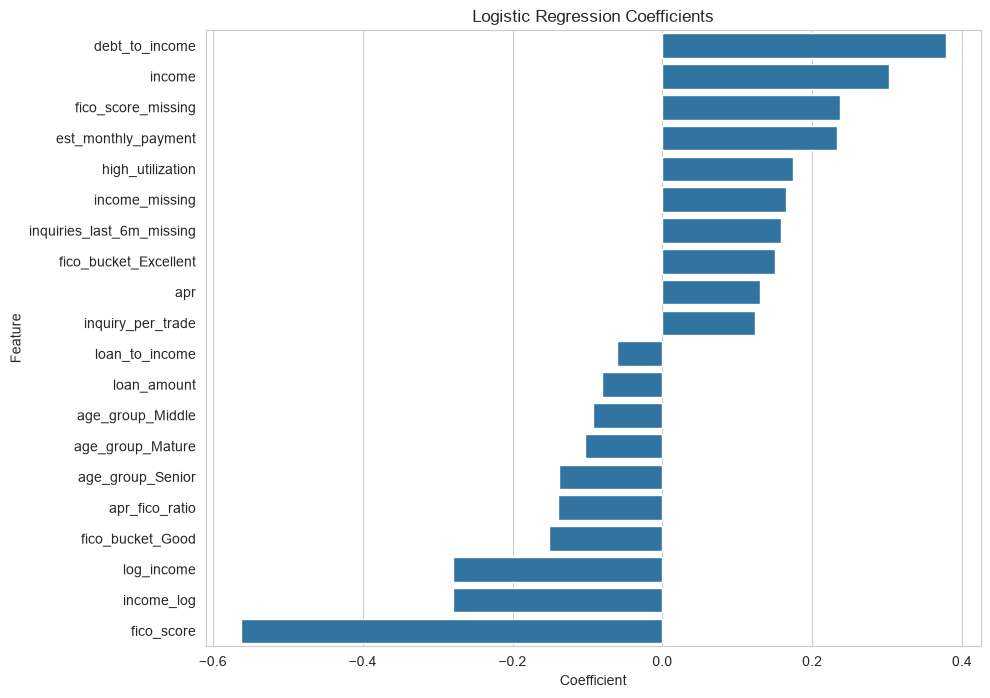

                      Feature  Coefficient
3              debt_to_income     0.378004
2                      income     0.302209
12         fico_score_missing     0.237107
27        est_monthly_payment     0.232618
18           high_utilization     0.174972
13             income_missing     0.165472
14  inquiries_last_6m_missing     0.158456
46      fico_bucket_Excellent     0.151052
9                         apr     0.130733
23          inquiry_per_trade     0.123209
43           fico_bucket_Fair     0.106444
11                        age     0.104242
39                   state_TX     0.083669
4             num_open_trades     0.067653
38                state_Other     0.060523
                      Feature  Importance
21                    low_dti    0.072981
1                  fico_score    0.038162
12         fico_score_missing    0.037199
18           high_utilization    0.029831
14  inquiries_last_6m_missing    0.029125
3              debt_to_income    0.028042
13             inc

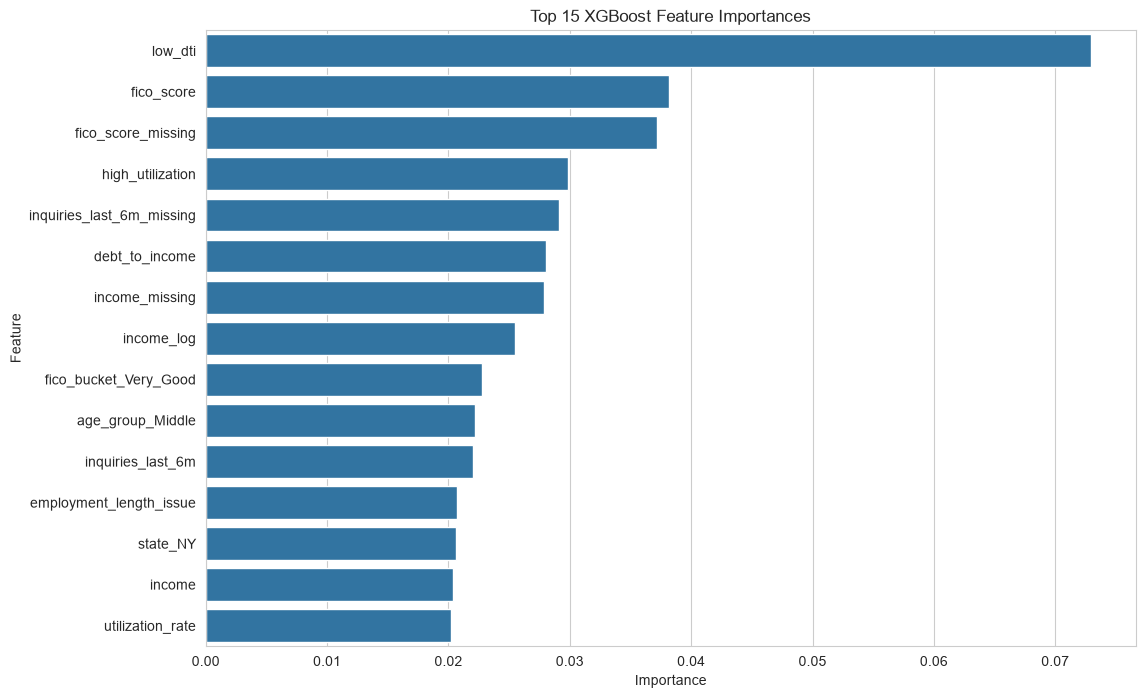

                      Feature  Importance
21                    low_dti    0.072981
1                  fico_score    0.038162
12         fico_score_missing    0.037199
18           high_utilization    0.029831
14  inquiries_last_6m_missing    0.029125
3              debt_to_income    0.028042
13             income_missing    0.027841
16                 income_log    0.025445
45      fico_bucket_Very_Good    0.022754
40           age_group_Middle    0.022206


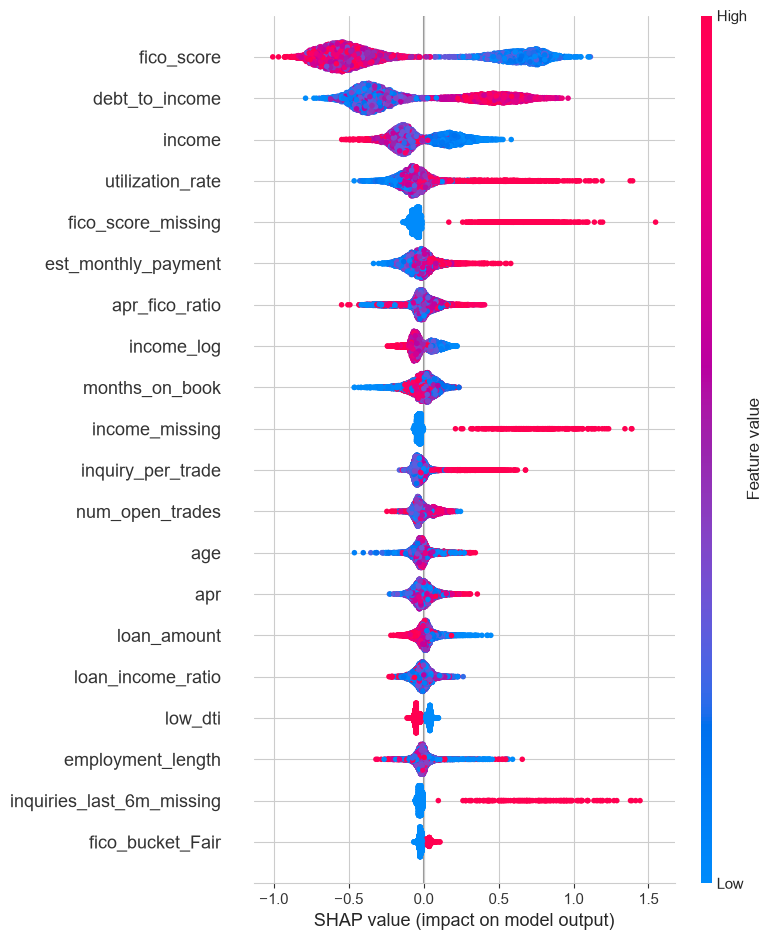

In [193]:
# Analyze feature importance
# Extract coefficients
coef_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': lr_pipeline.named_steps[
        'model'
    ].coef_[0]
})
coef_df = coef_df.sort_values(
    by='Coefficient',
    ascending=False
)
top_coeffs = pd.concat([
    coef_df.head(10),
    coef_df.tail(10)
])
plt.figure(figsize=(10,8))
sns.barplot(
    data=top_coeffs,
    x='Coefficient',
    y='Feature'
)
plt.title(
    'Logistic Regression Coefficients'
)
plt.show()
print (coef_df.head(15))
importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': xgb_model.feature_importances_
})
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)
print(importance_df.head(15))
plt.figure(figsize=(12,8))
sns.barplot(
    data=importance_df.head(15),
    x='Importance',
    y='Feature'
)
plt.title(
    'Top 15 XGBoost Feature Importances'
)
plt.show()
top10_features = importance_df.head(10)
print(top10_features)
import shap
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)
shap.summary_plot(shap_values,X_test)

### 6.2 Key Drivers of Default


                      Feature  Importance
21                    low_dti    0.072981
1                  fico_score    0.038162
12         fico_score_missing    0.037199
18           high_utilization    0.029831
14  inquiries_last_6m_missing    0.029125
3              debt_to_income    0.028042
13             income_missing    0.027841
16                 income_log    0.025445
45      fico_bucket_Very_Good    0.022754
40           age_group_Middle    0.022206
6           inquiries_last_6m    0.021998
15    employment_length_issue    0.020682
37                   state_NY    0.020642
2                      income    0.020406
5            utilization_rate    0.020237


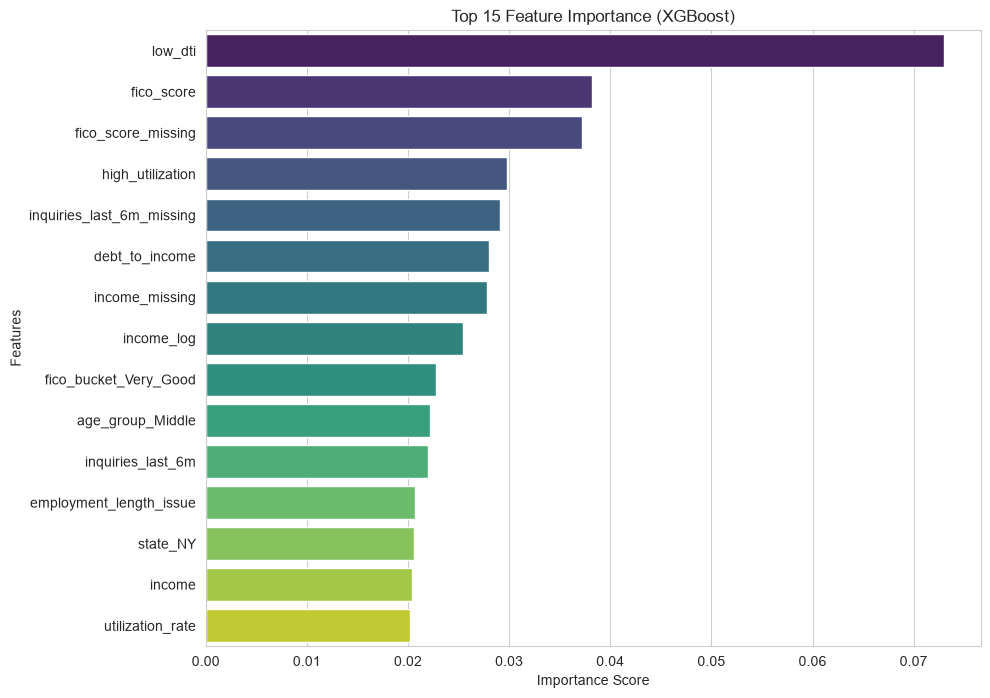

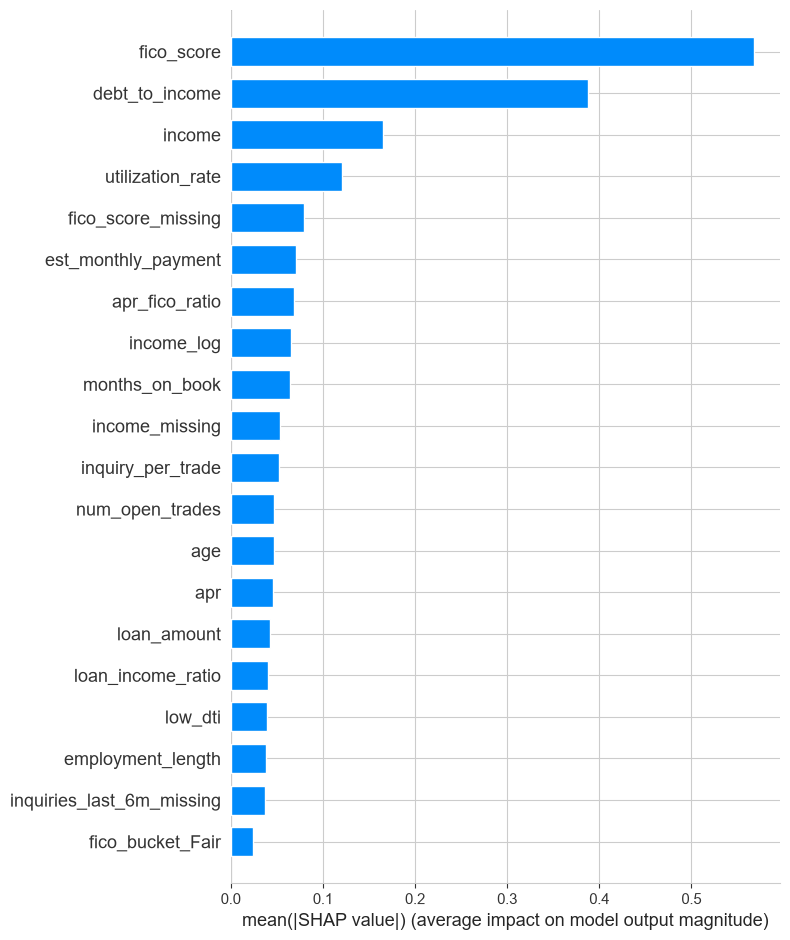

In [194]:
# Interpret key drivers
# Get feature importance
importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': xgb_model.feature_importances_
})
# Sort descending
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)
# Top 15 features
top15 = importance_df.head(15)
print(top15)
plt.figure(figsize=(10,8))
sns.barplot(
    data=top15,
    x='Importance',
    y='Feature',
    palette='viridis'
)
plt.title('Top 15 Feature Importance (XGBoost)')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()
shap.summary_plot(
    shap_values,
    X_test,
    plot_type="bar"
)

In [195]:
#save model and metrics
import os
import json
import joblib
os.makedirs(
    "./outputs/models",
    exist_ok=True
)
os.makedirs(
    "./outputs/metrics",
    exist_ok=True
)
joblib.dump(
    xgb_model,
    "./outputs/models/xgb_model.pkl"
)
metrics = {
    "auc": float(auc_xgb),
    "ks": float(ks_xgb),
    "pr_auc": float(pr_auc_xgb)
}
with open(
    "./outputs/metrics/metrics.json",
    "w"
) as f:
    json.dump(
        metrics,
        f,
        indent=4
    )
import os

os.makedirs(
    "./outputs/models",
    exist_ok=True
)
xgb_model.save_model(
    "./outputs/models/xgb_model.json"
)
print("Model saved successfully!")

comparison = {
    "LogisticRegression": {
        "auc": float(auc_lr),
        "ks": float(ks_lr),
        "pr_auc": float(pr_auc_lr)
    },

    "XGBoost": {
        "auc": float(auc_xgb),
        "ks": float(ks_xgb),
        "pr_auc": float(pr_auc_xgb)
    },

    "winner": "XGBoost"
}

with open(
    "./outputs/models/model_comparison.json",
    "w"
) as f:

    json.dump(
        comparison,
        f,
        indent=4
    )    
results = []
for depth in [3, 5, 7]:
    model = XGBClassifier(
        max_depth=depth,
        n_estimators=200,
        learning_rate=0.05,
        random_state=42
    )
    auc = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring='roc_auc'
    ).mean()
    results.append(
        {
            "max_depth": depth,
            "auc": auc
        }
    )
results_df = pd.DataFrame(
    results
)
print (results_df)
results_df.to_csv(
    "./outputs/models/parameter_sweep.csv",
    index=False
)

Model saved successfully!
   max_depth       auc
0          3  0.710593
1          5  0.693142
2          7  0.674325


## 7. Discussion & Next Steps

### 7.1 Model Assumptions

TODO: Discuss assumptions made by your models:
- Logistic Regression assumptions (linearity, independence, etc.)
- Tree-based model assumptions
- Any data assumptions

### 7.2 Potential Data Leakage

TODO: Discuss potential sources of data leakage:
- Features that might contain information about the target
- Temporal considerations
- Other leakage risks

### 7.3 Model Improvements

TODO: Discuss how you would improve model performance:
- Additional feature engineering
- Hyperparameter tuning
- Ensemble methods
- External data sources
- Handling class imbalance

### 7.4 Production Considerations

TODO: Discuss production deployment considerations:
- Model monitoring
- Performance degradation
- Scalability
- Interpretability requirements
- Regulatory compliance

---

## Summary

TODO: Provide a brief summary of your findings:
- Best performing model and why
- Key insights about default risk
- Recommendations for deployment

---


7.1 Model Assumptions

This project employed both Logistic Regression and XGBoost to predict loan default rate. While both models achieved strong predictive performance, each model relies on specific assumptions and data conditions.
1. Logistic Regression Assumptions
Key assumptions include for Logistic Regression:
Linearity of the log-odds: The model assumes that the relationship between predictor variables and the log-odds of default is linear.
Independence of observations: Each loan observation is assumed to be independent from all others.
Low multicollinearity: Predictor variables should not be highly correlated with one another, as multicollinearity can lead to unstable coefficient estimates.
No extreme influence from outliers: Although preprocessing was performed, extreme observations may still affect model estimates.
Sufficient sample size: Logistic Regression generally requires an adequate number of observations for stable parameter estimation.
In this study, feature engineering, outlier treatment, and correlation analysis were conducted to help satisfy these assumptions.
2. Tree-Based Model Assumptions
Key assumptions include for Xgboost:
Compared with Logistic Regression, XGBoost makes fewer assumptions about the underlying data.
Observations are assumed to be independent.
Historical patterns observed in the training data are expected to remain relevant for future predictions.
Important relationships can be captured through recursive tree splitting.
The training data is representative of the population on which predictions will be made.
Unlike Logistic Regression, XGBoost does not assume:
Linear relationships between variables and the target.
Normally distributed variables.
Equal variance across observations.
As a result, XGBoost is often more flexible when dealing with complex credit risk datasets.
3. Data Assumptions
The key assumptions were made regarding the dataset:
The target variable (default_12m) accurately reflects whether a borrower defaulted.Input variables such as income, FICO score, debt-to-income ratio, and utilization rate are assumed to be measured accurately.Missing values were imputed using median values, assuming that missing observations do not introduce systematic bias.
The train and test samples are assumed to come from the same underlying population.Future borrower behavior is assumed to follow patterns similar to those observed in the historical dataset.Potential target leakage variables were removed or carefully reviewed before model development.The both results indicate that both Logistic Regression and XGBoost are effective tools for credit risk prediction. The logistic Regression offers greater interpretability and transparency, while XGBoost provides greater modeling flexibility and slightly stronger predictive performance. The strong cross-validation AUC scores suggest good generalization performance; however, model performance may vary if future economic conditions differ significantly from those represented in the training data.

7.2 Potential Data Leakage

1. Features Potentially Containing Target Information:
Some variables in the dataset may contain information that is highly correlated with future default outcomes.
The leakage data variables include:  'origination_year','origination_month','origination_quarter','days_past_due_current','total_payments_to_date','payment_ratio', ‘loan_id’， 'payment_to_income'.These variables describe a borrower's payment behavior and delinquency status. If they are measured after loan origination or close to the default observation period, they may indirectly reveal future default outcomes. During model development, an unusually high Cross-Validation AUC close to overfit siutation was observed, Therefore, special attention should be given to ensuring that only information available at the prediction date is included in the feature set.
2. Temporal Considerations:
Credit risk prediction is inherently a time-dependent problem.Potential risks include: Using repayment information collected after loan origination.Using delinquency measures recorded during the prediction horizon. Using cumulative payment variables that include future payments. A more robust approach would be to perform a time-based train-test split using loan vintages or origination dates rather than random sampling.
3. Other leakage risks:
Feature engineering can unintentionally introduce leakage when creating derived variables. Some variables such as 'payment_ratio','loan_income_ratio' and 'payment_to_income'. While these variables may improve predictive performance, it is important to ensure that they use only information available at the prediction date.Another potential source of leakage arises during preprocessing.

7.3 Model Improvements
1. Additional Feature Engineering
We can add bureau attributes and More informative features could be developed to better capture borrower risk characteristics.Such as: Interaction features between credit score and debt burden,Credit utilization change indicators,Loan amount relative to employment length,State-level default rate features,Vintage-adjusted risk indicators, Behavioral features based on payment patterns.
2. Hyperparameter Tuning
The current XGBoost model uses predefined parameters. Performance could potentially be improved through systematic hyperparameter optimization. The paratmerts to tune: max_depth,learning_rate,n_estimators,subsample,colsample_bytree,min_child_weight,gamma.
3. Ensemble Methods
Combining multiple models may have better perform than any individual model.
4. External Data Sources
The current model relies solely on information contained within the loan dataset. Additional external data could improve risk prediction.
The External sources include:
Bureau attribute by Experian/TU (such as perimer attribute versions)
Regional unemployment rates
Inflation and interest rate indicators
Credit bureau information
Bankruptcy records
Housing market indicators
Another company's data source (CK lightbox or Lending tree source data)
5. Handling Class Imbalance
The dataset contains a relatively low default rate (approximately 3%).
In the logisticRegression: created class weight.
In the xgboost: created Scale weight.
These methods may improve the Precision-Recall performance by increasing the model's ability to identify default cases.

7.4 Production Considerations
1. Model Monitoring: Once deployed, the modeling team should be continuously monitored to ensure prediction quality remains stable over time. The Key Performance Indexs (KPI) are:ROC-AUC,KS Statistic,Precision and Recall,PSI,Feature distribution changes
2. Performance Degradation: The model performance may decline due to changes in the consumer behavior, economic conditions, or other things. The potential causes should be include as here: economic recessions, changes in interest rates by Fed, shifts in applicant demographics, updated underwriting and strategy by credit risk strategy team, new products from Best egg company.
3. Scalability: The production systems must be capable of generating predictions efficiently for large volumes of loan applications. Such as the real-time scoring, The API deployment architecture, the computational requirements and other factors. The logistic Regression offers excellent scalability and low computational cost, making it suitable for high-volume real-time scoring. However, the XGBoost is more computationally intensive but can still be deployed efficiently using modern model-serving frameworks.
4. Interpretability Requirements: The logistic regression provides clear coefficient interpretation, transparent decision logic and very easier regulatory review and XGBoost provides stronger predictive power but requires additional explainability tools such as: Shap values. The Shap values can help explain why a particular borrower was classified as high risk.
5. Regulatory Compliance: The modeling team should be operate within highly regulated environments and must comply with applicable legal and regulatory requirements by credit risk goverment team. Such as: The fair lending requirements, model governance and documentation, explainability of credit decisions from AA letters, data privacy and protection, regular model validation and auditing and other factors.  and all model development steps, assumptions, feature engineering procedures, and validation results should be thoroughly documented to support governance and audit requirements.

7.5 Summary:
    
    The analysis includes exploratory data analysis, data quality assessment, feature engineering, and model development. Logistic Regression was selected as an interpretable baseline, while XGBoost was evaluated to capture potential nonlinear relationships and interactions. Special values and missing observations were identified and handled through appropriate preprocessing. Model evaluation considers discrimination, ranking performance, and the importance of evaluating generalization across origination vintages.

    1. Summary of Findings: This project developed and evaluated machine learning models to predict borrower default risk using historical loan and borrower information. Both Logistic Regression and XGBoost demonstrated strong predictive performance; however, XGBoost achieved the highest overall performance.
    2. Best Performing Model: Among the models evaluated, XGBoost was selected as the best-performing model. Logistic Regression achieved a good mean cross-validation ROC-AUC and XGBoost achieved a slightly higher ROC-AUC and XGBoost was able to capture nonlinear relationships and complex interactions among borrower characteristics, resulting in improved predictive accuracy.Although the performance improvement was modest, XGBoost consistently outperformed Logistic Regression across evaluation metrics while maintaining strong discriminatory power.Model performance is assessed using ROC-AUC, KS statistic, PR-AUC, and additional metrics relevant to an imbalanced credit risk dataset. Calibration and vintage-level performance are also evaluated to understand whether predicted probabilities are reliable and whether model performance remains stable over time. Model selection is based not only on predictive performance but also on interpretability, stability, calibration, and potential business applicability.
    3. Key Insights About Default Risk: The analysis identified several important drivers of borrower default:Delinquency history was the strongest predictor of future default. Lower FICO scores were associated with significantly higher default risk. Higher DTI increased the likelihood of default. High credit utilization indicated greater financial stress and elevated risk. Lower income levels and higher loan-to-income ratios were linked to weaker repayment capacity. Frequent recent credit inquiries were associated with increased default probability. These findings are consistent with established credit risk theory and common lending industry practices.
    - The dataset exhibits class imbalance, with default representing a relatively small proportion of observations.
    - Data quality issues include special missing-value codes and potentially inconsistent feature values.
    - Both Logistic Regression and XGBoost provide useful modeling benchmarks.
    - Temporal validation is important to assess the model's ability to generalize to future origination vintages.
    - Origination-time feature availability is critical to prevent data leakage and ensure realistic model performance estimates.
    4. Recommendations for Deployment: Before production deployment, the model should undergo additional validation, including out-of-time testing, calibration assessment, vintage-level stability analysis, and business impact evaluation. Further work should include threshold optimization aligned with lending objectives, model monitoring for population and performance drift, documentation of model limitations, and independent model validation.The final model should be selected based on a balance of predictive performance, calibration, stability, interpretability, and operational requirements rather than a single evaluation metric.Before deploying the model into a production environment, several recommendations should be considered: Deploy XGBoost as the primary risk model due to its superior predictive performance. Maintain Logistic Regression as a benchmark model because of its transparency and ease of explanation. Implement ongoing model monitoring using metrics such as AUC, KS, and PSI. Retrain the model periodically to account for changing borrower behavior and economic conditions. Use SHAP or other explainability techniques to provide transparency for risk decisions and regulatory reviews. Integrate additional data sources, including credit bureau attributes and application decision results, to further improve model performance. Monitor for potential data leakage and model drift to ensure long-term reliability. AUC tells us whether the model can rank borrowers by risk, but calibration tells us whether the predicted probabilities are accurate.Calibration is essential in credit risk modeling to ensure that predicted probabilities of default (PDs) accurately reflect observed default rates. While discrimination metrics such as ROC-AUC measure a model's ability to rank borrowers by risk, they do not assess the accuracy of predicted probabilities.
    5. Final Conclusion:Overall, the project successfully developed a high-performing credit risk prediction framework capable of identifying borrowers with elevated default risk. XGBoost achieved the strongest predictive performance, while both models highlighted the importance of delinquency history, credit quality, debt burden, and repayment capacity as key determinants of default. With proper monitoring, governance, and feature enhancements, the model could serve as a valuable tool for loan underwriting, risk management, and portfolio monitoring.